# Clase 25 · Formularios y dashboard en Google Colab

**Programación — ADMI 1301**

En este cuaderno practicamos los formularios de Colab, las operaciones básicas y la presentación de resultados con gráficos y tablas.

| Nivel | Ejercicio |
|---|---|
| 1 | Calculadora de operaciones |
| 2 | Calculadora de descuentos con IVA |
| 3 | Gráficos con datos ingresados en casillas |
| 4 | Dashboard con datos de ejemplo |

**Para probarlo:** ejecuta las celdas en orden. En los formularios puedes cambiar los valores y volver a ejecutar.

## Nivel 1 · Calculadora de operaciones con casillas

Partimos de la suma del modelo del profesor y completamos su actividad **Tu turno**: un menú para elegir suma, resta, multiplicación o división, evitando dividir entre cero.


In [6]:
#@title Calculadora de dos números { display-mode: "form" }
#@markdown Escribe dos números, selecciona una operación y pulsa ejecutar (▶).
primer_numero = 12 #@param {type:"number"}
segundo_numero = 30 #@param {type:"number"}
operacion = "suma" #@param ["suma", "resta", "multiplicación", "división"]

if operacion == "suma":
    resultado = primer_numero + segundo_numero
elif operacion == "resta":
    resultado = primer_numero - segundo_numero
elif operacion == "multiplicación":
    resultado = primer_numero * segundo_numero
else:
    if segundo_numero == 0:
        resultado = None
        print("No se puede dividir entre cero. Cambia el segundo número.")
    else:
        resultado = primer_numero / segundo_numero

if resultado is not None:
    print(f"Resultado de {operacion}: {resultado:g}")


Resultado de suma: 42


**Comprobación rápida:** prueba `12 + 30 = 42`, `12 - 30 = -18`, `12 × 30 = 360`, `12 ÷ 30 = 0.4`. En división, si el segundo número es cero, aparece una advertencia. El menú se crea con `#@param` y la operación se selecciona mediante `if`/`elif`/`else`.

## Nivel 2. Dar formato al resultado: calculadora de descuento

Ahora hay tres tipos de casilla (número, deslizador y casilla de verificación) y el resultado se muestra en una **tarjeta con formato**. **Recursos nuevos:** `#@markdown` para texto con formato, `display(HTML(...))` para tarjetas y `{valor:,.0f}` para escribir números con separador de miles.

In [7]:
#@title Calculadora de descuento { display-mode: "form" }
#@markdown ### Datos del producto
precio_original = 85000 #@param {type:"number"}
descuento = 20 #@param {type:"slider", min:0, max:50, step:5}
incluir_iva = False #@param {type:"boolean"}

from IPython.display import display, HTML

precio_final = precio_original * (1 - descuento / 100)
ahorro = precio_original - precio_final
nota = "Sin IVA"
if incluir_iva:
    precio_final = precio_final * 1.19
    nota = "IVA del 19% incluido"

display(HTML(f"""
<div style="font-family:Arial,sans-serif; background:#eef4fc; border-left:6px solid #2a78d6;
            border-radius:6px; padding:14px 20px; max-width:380px; color:#0b0b0b">
  <div style="font-size:13px; color:#52514e">Precio final</div>
  <div style="font-size:34px; font-weight:bold; color:#2a78d6">${precio_final:,.0f}</div>
  <div style="font-size:13px">Ahorras ${ahorro:,.0f} ({descuento}% de descuento) · {nota}</div>
</div>
"""))

## Nivel 3. Un gráfico que cambia con las casillas

La aplicación recibe tres nombres con sus valores y los muestra como barras, líneas o torta. **Recursos nuevos:** casillas de texto y lista desplegable (`#@param ["barras", "líneas", "torta"]`) y el gráfico con `matplotlib` (`plt.subplots`, `ax.bar`, `plt.show`).

Total: 360   Promedio: 120.0   Mayor: Febrero


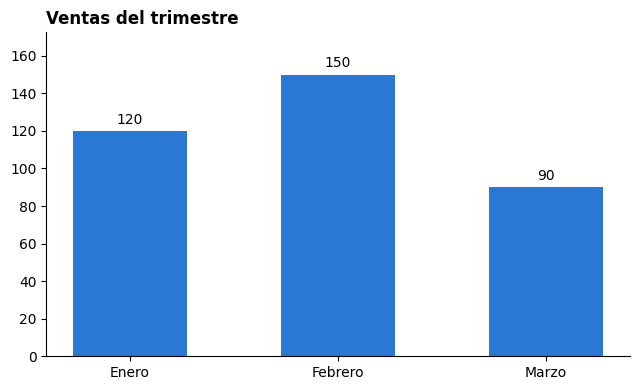

In [8]:
#@title Tres valores en un gráfico { display-mode: "form" }
#@markdown Escribe un nombre y un valor para cada dato, elige el tipo de gráfico y pulsa ejecutar.
titulo = "Ventas del trimestre" #@param {type:"string"}
nombre_1 = "Enero" #@param {type:"string"}
valor_1 = 120 #@param {type:"number"}
nombre_2 = "Febrero" #@param {type:"string"}
valor_2 = 150 #@param {type:"number"}
nombre_3 = "Marzo" #@param {type:"string"}
valor_3 = 90 #@param {type:"number"}
tipo_grafico = "barras" #@param ["barras", "líneas", "torta"]

import matplotlib.pyplot as plt

nombres = [nombre_1, nombre_2, nombre_3]
valores = [valor_1, valor_2, valor_3]
AZUL = "#2a78d6"
COLORES = ["#2a78d6", "#eb6834", "#1baf7a"]

if tipo_grafico == "torta" and (min(valores) < 0 or sum(valores) == 0):
    print("La torta necesita valores positivos. Cambia los valores o el tipo de gráfico.")
else:
    print(f"Total: {sum(valores):g}   Promedio: {sum(valores) / 3:.1f}   Mayor: {nombres[valores.index(max(valores))]}")
    fig, ax = plt.subplots(figsize=(6.5, 4))
    if tipo_grafico == "barras":
        barras = ax.bar(nombres, valores, color=AZUL, width=0.55)
        ax.bar_label(barras, fmt="%g", padding=3)
    elif tipo_grafico == "líneas":
        ax.plot(nombres, valores, color=AZUL, marker="o", linewidth=2)
        for n, v in zip(nombres, valores):
            ax.annotate(f"{v:g}", (n, v), textcoords="offset points", xytext=(0, 8), ha="center")
    else:
        ax.pie(valores, labels=nombres, colors=COLORES, autopct="%1.0f%%",
               startangle=90, counterclock=False,
               wedgeprops={"edgecolor": "white", "linewidth": 2})
    ax.set_title(titulo, loc="left", fontweight="bold")
    if tipo_grafico != "torta":
        ax.spines[["top", "right"]].set_visible(False)
        ax.set_ylim(min(0, min(valores) * 1.1), max(valores) * 1.15 if max(valores) > 0 else 1)
    plt.tight_layout()
    plt.show()

## Nivel 4. Un dashboard solo para mirar

Aquí **la persona no escribe nada**: el autor (tú) carga los datos, los trata y deja listo lo que se va a mostrar. Por eso hay dos celdas:

1. **Preparación (la hace el autor).** Cargar, limpiar y resumir los datos. Esta celda no tiene que ser bonita; es tu trabajo con pandas.
2. **Dashboard (lo que ve el usuario).** Usa solo los resultados de la celda anterior: tarjetas con las cifras clave, tres gráficos en una sola figura y una tabla con estilo.

**Recursos nuevos:** tarjetas en HTML, `plt.subplots(1, 3)` para varios gráficos y `resumen.style` para la tabla.

In [9]:
# --- PREPARACIÓN (autor): datos inventados de ventas por mes y sede ---
import pandas as pd

meses = ["Ene", "Feb", "Mar", "Abr", "May", "Jun"]
datos = pd.DataFrame({
    "mes":   meses * 3,
    "sede":  ["Norte"] * 6 + ["Sur"] * 6 + ["Centro"] * 6,
    "ventas": [92, 98, 105, 110, 118, 126,
               85, 80, 88, 91, 95, 99,
               120, 118, 126, 131, 128, 140],
})
meta_mensual = {"Norte": 100, "Sur": 95, "Centro": 125}

# Ventas por mes y sede (columnas = sedes)
por_mes = datos.pivot_table(index="mes", columns="sede", values="ventas", aggfunc="sum").loc[meses]

# Resumen por sede
resumen = datos.groupby("sede").agg(total=("ventas", "sum"), promedio=("ventas", "mean"), maximo=("ventas", "max"))
resumen["meta"] = pd.Series(meta_mensual) * len(meses)
resumen["cumplimiento"] = resumen["total"] / resumen["meta"]
resumen = resumen.sort_values("total", ascending=False)
resumen

,total,promedio,maximo,meta,cumplimiento
sede,,,,,
Centro,763,127.166667,140,750,1.017333
Norte,649,108.166667,126,600,1.081667
Sur,538,89.666667,99,570,0.943860


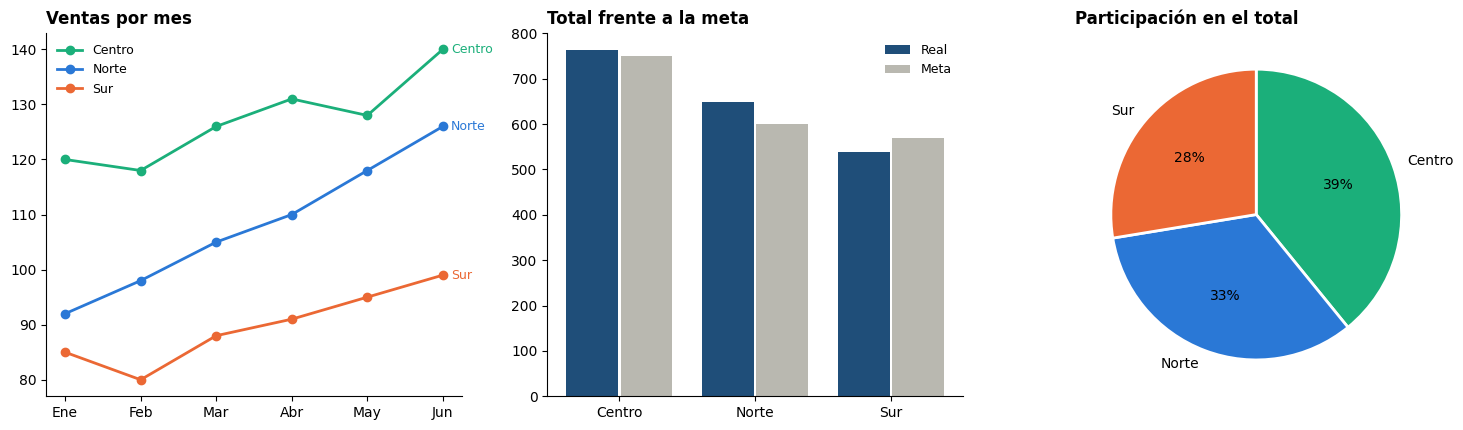

,total,promedio,maximo,meta,cumplimiento
sede,,,,,
Centro,763,127.2,140,750,102%
Norte,649,108.2,126,600,108%
Sur,538,89.7,99,570,94%


In [10]:
#@title Dashboard de ventas { display-mode: "form" }
from IPython.display import display, HTML
import matplotlib.pyplot as plt

COLOR_SEDE = {"Norte": "#2a78d6", "Sur": "#eb6834", "Centro": "#1baf7a"}   # cada sede conserva su color
GRIS = "#b9b8b0"

# ---- Cifras clave
total = resumen["total"].sum()
cumpl_global = total / resumen["meta"].sum()
mejor_sede = resumen["total"].idxmax()
mejor_mes = por_mes.sum(axis=1).idxmax()

def tarjeta(titulo, valor, detalle=""):
    return f"""
    <div style="flex:1; min-width:150px; background:#f5f7fa; border-top:4px solid #2a78d6; border-radius:6px; padding:10px 14px; color:#0b0b0b">
      <div style="font-size:12px; color:#52514e">{titulo}</div>
      <div style="font-size:26px; font-weight:bold">{valor}</div>
      <div style="font-size:12px; color:#52514e">{detalle}</div>
    </div>"""

display(HTML(f"""
<div style="font-family:Arial,sans-serif">
  <div style="font-size:22px; font-weight:bold; color:#1F4E79">Ventas por sede, enero a junio</div>
  <div style="font-size:13px; color:#52514e; margin-bottom:10px">Datos de ejemplo (inventados)</div>
  <div style="display:flex; gap:12px; flex-wrap:wrap">
    {tarjeta("Ventas totales", f"{total:,.0f}")}
    {tarjeta("Cumplimiento de la meta", f"{cumpl_global:.0%}")}
    {tarjeta("Mejor sede", mejor_sede, f"{resumen.loc[mejor_sede, 'total']:,.0f} en ventas")}
    {tarjeta("Mes más fuerte", mejor_mes)}
  </div>
</div>
"""))

# ---- Tres gráficos en una figura
fig, axs = plt.subplots(1, 3, figsize=(15, 4.4))

for sede in por_mes.columns:                                   # 1) tendencia por mes
    axs[0].plot(por_mes.index, por_mes[sede], color=COLOR_SEDE[sede], marker="o", linewidth=2, label=sede)
    axs[0].annotate(sede, (por_mes.index[-1], por_mes[sede].iloc[-1]), textcoords="offset points",
                    xytext=(6, 0), va="center", color=COLOR_SEDE[sede], fontsize=9)
axs[0].set_title("Ventas por mes", loc="left", fontweight="bold")
axs[0].spines[["top", "right"]].set_visible(False)
axs[0].legend(frameon=False, loc="upper left", fontsize=9)

x = range(len(resumen))                                         # 2) total frente a la meta
axs[1].bar([i - 0.2 for i in x], resumen["total"], width=0.38, color="#1F4E79", label="Real")
axs[1].bar([i + 0.2 for i in x], resumen["meta"], width=0.38, color=GRIS, label="Meta")
axs[1].set_xticks(list(x))
axs[1].set_xticklabels(resumen.index)
axs[1].set_title("Total frente a la meta", loc="left", fontweight="bold")
axs[1].spines[["top", "right"]].set_visible(False)
axs[1].legend(frameon=False, fontsize=9)

axs[2].pie(resumen["total"], labels=resumen.index, colors=[COLOR_SEDE[s] for s in resumen.index],   # 3) participación
           autopct="%1.0f%%", startangle=90, counterclock=False, wedgeprops={"edgecolor": "white", "linewidth": 2})
axs[2].set_title("Participación en el total", loc="left", fontweight="bold")

plt.tight_layout()
plt.show()

# ---- Tabla con estilo
display(resumen.style
        .format({"total": "{:,.0f}", "promedio": "{:.1f}", "maximo": "{:,.0f}", "meta": "{:,.0f}", "cumplimiento": "{:.0%}"})
        .background_gradient(subset=["cumplimiento"], cmap="Blues")
        .set_caption("Resumen por sede"))

## Pruebas realizadas

- **Calculadora:** permite sumar, restar, multiplicar y dividir; avisa si se intenta dividir entre cero.
- **Descuentos:** se puede cambiar el precio, el porcentaje y la opción de IVA.
- **Gráficos:** permite escoger barras, líneas o torta.
- **Dashboard:** presenta las ventas de ejemplo por sede, el cumplimiento de metas y su distribución en tres gráficos y una tabla.

Los valores del dashboard son datos de práctica de la clase.